## Задание 1

Модуль лингвистической предобработки текста является одним из важнейших компонентов современных TTS систем.
Стандартный набор преобразований над текстом включает в себя:
- нормализацию 
- токенизацию 
- построение транскрипции

Нормализация подразумевает расшифровку числовых последовательностей, дат, оббревиатур, иноязычных вставок, сокращений и т.д. (не путать с приведением к нормальной форме слов - принятой терминологиией в NLP).

Токенизация - разбиение текста на предложения и слова.

Построение транскрипции позволяет получить из графемного фонемное представление текста. На этом же этапе разрешается пробелма расстановки ударений. 

**Инструкция по установке и подключению сторонних библиотек из репозиториев (если не устанавливается через pip)**
1. Склонировать репозиторий `!git clone путь к репозиторию`

2. Добавить корень репо в PATH `sys.path.append("корень склонированного репо")`

3. Установить необходимые зависимости для репо `!pip install название библиотеки`

In [ ]:
# установка необходимых библиотек
!pip install torch

In [ ]:
# Импорт необходимых библиотек

import numpy as np
import os
import sys
import uuid
import torch

from google.colab import drive
from google.colab import files

In [ ]:
#@markdown Plotting style (default is styled like plots from [FiveThirtyeight.com](https://fivethirtyeight.com/))
matplotlib_style = 'seaborn' #@param ['fivethirtyeight', 'bmh', 'ggplot', 'seaborn', 'default', 'Solarize_Light2', 'classic', 'dark_background', 'seaborn-colorblind', 'seaborn-notebook']
import matplotlib.pyplot as plt
plt.style.use(matplotlib_style)
%matplotlib inline

#@markdown Resolution of the plot outputs (`retina` is the highest resolution)
notebook_screen_res = 'retina' #@param ['retina', 'png', 'jpeg', 'svg', 'pdf']
%config InlineBackend.figure_format = notebook_screen_res

In [ ]:
# ваш номер
my_id = uuid.uuid4().hex
print(my_id)

In [ ]:
my_id = "fd57a51a2db646079dfd217a08b6c760"

In [ ]:
# Исходный текст
input_text = "В 1785 г в городе Augsburg случилось странное проишествие. Группа в 18 человек, где каждый весил не менее 100 кг, устроила праздник на втором этаже деревянного здания."

In [ ]:
!git clone https://github.com/natasha/razdel

Cloning into 'razdel'...
remote: Enumerating objects: 505, done.
remote: Counting objects: 100% (162/162), done.
remote: Compressing objects: 100% (107/107), done.
remote: Total 505 (delta 88), reused 101 (delta 51), pack-reused 343
Receiving objects: 100% (505/505), 42.67 MiB | 18.58 MiB/s, done.
Resolving deltas: 100% (297/297), done.


In [ ]:
sys.path.append("/content/razdel")

In [ ]:
!pip install razdel

In [ ]:
# Используйте razdel отсюда https://github.com/natasha/razdel
from razdel import tokenize, sentenize


def tokenize_by_sent(text):
   "Возвращает список токенизированных предложений"
   #tokens = list(tokenize(text))
   sentences = list(sentenize(text))
   return [_.text for _ in sentences] # tokens

In [ ]:
sentences = tokenize_by_sent(input_text)
print(sentences)

['В 1785 г в городе Augsburg случилось странное проишествие.', 'Группа в 18 человек, где каждый весил не менее 100 кг, устроила праздник на втором этаже деревянного здания.']


Токенизация на предложения нужна и при подготовке обучающих баз и при инференсе системы. Обучать модель на длинных текстах как правило нецелесообразно. 

Токенизация на слова может понадобится для получения границ слов, получения знаков препринания, может требоваться для более качественной нормализации.

In [ ]:
!git clone https://github.com/snakers4/russian_stt_text_normalization

Cloning into 'russian_stt_text_normalization'...
remote: Enumerating objects: 48, done.
remote: Counting objects: 100% (48/48), done.
remote: Compressing objects: 100% (36/36), done.
remote: Total 48 (delta 23), reused 19 (delta 9), pack-reused 0
Unpacking objects: 100% (48/48), done.


In [ ]:
sys.path.append("russian_stt_text_normalization")

In [ ]:
# Для реализации функции воспользуйтесь инструментом Normalizer из этого репозитория https://github.com/snakers4/russian_stt_text_normalization
# подсказка по путям sys.path.append("russian_stt_text_normalization")
from normalizer import Normalizer


def normalize(text):
  "Возвращает нормализованное предложение"
  norm = Normalizer(jit_model='russian_stt_text_normalization/jit_s2s.pt')
  return norm.norm_text(text)

In [ ]:
norm_sentences = [normalize(sentence) for sentence in sentences]
print(norm_sentences)

100%|██████████| 1/1 [00:00<00:00,  4.78it/s]

['В тысяча семьсот восемьдесят пятый год в городе огсбург случилось странное проишествие.', 'Группа в восемнадцать человек, где каждый весил не менее ста килограммов, устроила праздник на втором этаже деревянного здания.']


Нормализация текста - сложная задача. Далеко не всегда открытые решения хорошо с ней справляются. Нормализация на основе лингвистических баз и правил может справляться с задачей лучше, чем нейросетевая модель.

In [ ]:
!git clone https://github.com/nsu-ai/russian_g2p

Cloning into 'russian_g2p'...
remote: Enumerating objects: 878, done.
remote: Counting objects: 100% (24/24), done.
remote: Compressing objects: 100% (20/20), done.
remote: Total 878 (delta 6), reused 9 (delta 4), pack-reused 854
Receiving objects: 100% (878/878), 33.92 MiB | 16.08 MiB/s, done.
Resolving deltas: 100% (586/586), done.


In [ ]:
os.rename("russian_g2p", "root_russian_g2p")
os.replace("root_russian_g2p/russian_g2p", "russian_g2p")

In [ ]:
sys.path.append("russian_g2p")

In [ ]:
!pip install -r root_russian_g2p/requirements.txt

  Cloning https://github.com/bond005/rnnmorph.git to /tmp/pip-req-build-6g7glonc
  Running command git clone -q https://github.com/bond005/rnnmorph.git /tmp/pip-req-build-6g7glonc
     |████████████████████████████████| 378kB 24.0MB/s 
     |████████████████████████████████| 61kB 6.4MB/s 
     |████████████████████████████████| 8.2MB 22.5MB/s 
  Created wheel for dawg: filename=DAWG-0.8.0-cp37-cp37m-linux_x86_64.whl size=859812 sha256=0d3b97b129cd7bd525640d3294a5ebdaff226930d96190a4dcabe35ae7f7be66
  Stored in directory: /root/.cache/pip/wheels/3d/1f/f0/a5b1f9d02e193c997d252c33d215f24dfd7a448bc0166b2a12
  Created wheel for rnnmorph: filename=rnnmorph-0.4.0-cp37-none-any.whl size=10529959 sha256=d13ed164055efc13b8263f7720d053817678952926493b48c0b78b176118ed74
  Stored in directory: /tmp/pip-ephem-wheel-cache-g35vcju3/wheels/60/f3/e1/cc032402ccbf420e212766beba51cbd11d581fbd7cd1d9658a
  Created wheel for russian-tagsets: filename=russian_tagsets-0.6-cp37-none-any.whl size=24635 sha256=669

In [ ]:
from russian_g2p.Accentor import Accentor
from russian_g2p.Grapheme2Phoneme import Grapheme2Phoneme
import re

In [ ]:
# Для реализации используйте Accentor отсюда https://github.com/nsu-ai/russian_g2p
# Для решения проблем с импортом в этой библиотеке лучше перенести папку russian_g2p ближе к корню
# os.rename("russian_g2p", "root_russian_g2p")
# os.replace("root_russian_g2p/russian_g2p", "russian_g2p")

def g2p(text):
  "Возвращает список из фонем входящего текста"
  text = re.sub('[^a-яА-Я ]+', '', text) # only letters and spaces
  accentor = Accentor()
  text = [[x] for x in text.split()]
  accents = accentor.do_accents(text) #[['конференция'], ['диалог']]
  transcriptor = Grapheme2Phoneme()
  result = [transcriptor.word_to_phonemes(word) for word in accents[0]]
  flatten_result = []
  for i, lst in enumerate(result):
    for j in range(len(lst)):
      flatten_result.append(lst[j])
    #if j == len(lst) - 1 and i < len(result) - 1:
    #  flatten_result.append(" ") # add spaces
  print(flatten_result)
  return flatten_result

In [ ]:
norm_sentences

['В тысяча семьсот восемьдесят пятый год в городе огсбург случилось странное проишествие.',
 'Группа в восемнадцать человек, где каждый весил не менее ста килограммов, устроила праздник на втором этаже деревянного здания.']

In [ ]:
phonemes_sequences = [g2p(sentence) for sentence in norm_sentences]
print(phonemes_sequences)

/content/russian_g2p/Accentor.py:559: UserWarning: Word `огсбург` is unknown!
  warnings.warn(err_msg)
/content/russian_g2p/Accentor.py:559: UserWarning: Word `проишествие` is unknown!
  warnings.warn(err_msg)
/content/russian_g2p/Grapheme2Phoneme.py:96: UserWarning: `огсбург`: the accent for this word is unknown!
  warnings.warn(f'`{source_word}`: the accent for this word is unknown!')
/content/russian_g2p/Grapheme2Phoneme.py:96: UserWarning: `проишествие`: the accent for this word is unknown!
  warnings.warn(f'`{source_word}`: the accent for this word is unknown!')


['F', 'T', 'Y0', 'S0', 'I', 'TSH0', 'A', 'S0', 'I', 'M0', 'S', 'O0', 'T', 'V', 'O0', 'S0', 'I', 'M0', 'D0', 'I', 'S0', 'I', 'T', 'P0', 'A0', 'T', 'Y', 'J0', 'G', 'O0', 'T', 'F', 'G', 'O0', 'R', 'A', 'D0', 'I', 'A', 'G', 'Z', 'B', 'U', 'R', 'K', 'S', 'L', 'U', 'TSH0', 'I0', 'L', 'A', 'S0', 'S', 'T', 'R', 'A0', 'N', 'A', 'J0', 'I', 'P', 'R', 'A', 'I', 'SH', 'Y', 'S', 'T', 'V0', 'I', 'J0', 'I']
['G', 'R', 'U0', 'P', 'A', 'F', 'V', 'A', 'S0', 'I', 'M', 'N', 'A0', 'TS', 'A', 'T0', 'TSH0', 'I', 'L', 'A', 'V0', 'E0', 'K', 'G', 'D0', 'E0', 'K', 'A0', 'ZH', 'D', 'Y', 'J0', 'V0', 'E0', 'S0', 'I', 'L', 'N0', 'I', 'M0', 'E0', 'N0', 'I', 'J0', 'I', 'S', 'T', 'A0', 'K0', 'I', 'L', 'A', 'G', 'R', 'A', 'M', 'A', 'F', 'U', 'S', 'T', 'R', 'O0', 'I', 'L', 'A', 'P', 'R', 'A0', 'Z0', 'N0', 'I', 'K', 'N', 'A', 'F', 'T', 'A', 'R', 'O0', 'M', 'Y', 'T', 'A', 'ZH', 'E0', 'D0', 'I', 'R0', 'I', 'V0', 'A0', 'N', 'A', 'V', 'A', 'Z', 'D', 'A0', 'N0', 'I', 'J0', 'A']
[['F', 'T', 'Y0', 'S0', 'I', 'TSH0', 'A', 'S0', 'I

/content/russian_g2p/Accentor.py:559: UserWarning: Word `килограммов` has too many accent variants!
  warnings.warn(err_msg)
/content/russian_g2p/Grapheme2Phoneme.py:96: UserWarning: `килограммов`: the accent for this word is unknown!
  warnings.warn(f'`{source_word}`: the accent for this word is unknown!')


In [ ]:
# Сохраняем результат себе
with open(f"result_1_{my_id}.txt", 'w') as f_out:
  for sequence in phonemes_sequences:
    f_out.write(f'{" ".join(sequence)}\n')

In [ ]:
files.download(f"result_1_{my_id}.txt") 

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Насколько можно видеть, итоговая последовательность может представлять из себя простой список из фонем, в котором не видно границ слов или знаков препинания. В самом простом варианте, границы слов можно обозначить пробельным символом. Однако знаки препинания лучше исключить из финальной последовательности, т.к. их наличие будет мешать модели выстраивать матрицу внимания (какой длительности будет многоточие или знак вопроса?).

## Задание 2

Пайплайн получения признаков из аудио для TTS может быть достаточно сложным.
Последовательность обработчиков и их параметры будут зависеть в том числе и от особенностей вокодера. 
Наиболее распространенным вариантом акустических признаков является логарифмированная мел-спектрограмма.

Задание - реализовать функции построения мел-спектрограммы с заданными параметрами.

Общий вид пайплайна такой: Входной сигнал -> Pre-emphasis -> STFT -> Магнитуда-> Мел-скейл -> Логарифмирование

In [ ]:
# примонтировать свой диск (куда заранее положили нужный wav файл)
drive.mount("/content/gdrive")

Mounted at /content/gdrive


In [ ]:
!ls "/content/gdrive/MyDrive/Colab Notebooks/tts_files"

decoder_state_dict.pt  gettysburg10.wav  tts_notebook.ipynb
encoder_output.npy     sample.wav


In [ ]:
import librosa
import IPython.display as ipd

In [ ]:
# загрузки входного сигнала (скорее всего путь будет таким 'gdrive/MyDrive/audio_sample/example.wav') 
# можно воспользоваться librosa

def read_wave(wave_path):
  "возвращает волну и sample rate"
  wave, sr = librosa.core.load(wave_path)
  return wave, sr

wave_path = "/content/gdrive/MyDrive/Colab Notebooks/tts_files/sample.wav"
wave, sr = read_wave(wave_path)

In [ ]:
print(f"Sample rate = {sr}")
print(f"Wave max = {np.max(wave)} Wave min {np.min(wave)}")
print(f"Wave samples = {wave.shape}")
print(f"Sample type = {type(wave[0])}")

Sample rate = 22050
Wave max = 0.4473876953125 Wave min -0.579498291015625
Wave samples = (63744,)
Sample type = <class 'numpy.float32'>


In [ ]:
player = ipd.Audio(wave, rate=sr)
ipd.display(player)

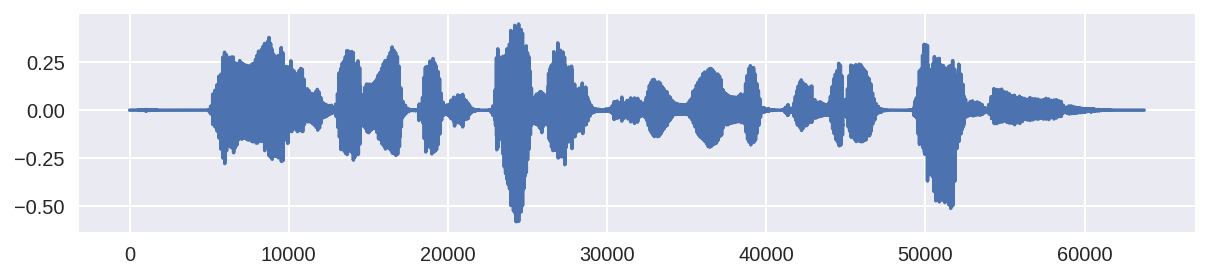

In [ ]:
plt.figure(figsize=(10, 2))
plt.plot(wave);

Данные могут быть в формате float32 или int16 (обычно ...). Нужно привести к формату float32 в диапазоне значений [0, 1]. Стоит обратить внимание на максимальное и минимальное значение (если значения близки к максимум и минимуму диапазона, возможно они были нормализованы или даже клипированы).

In [ ]:
# Pre-emphasis
# y[n] = x[n] - coef * x[n-1]
# coef = 0.97

def preemphasis(x, coef=0.97):
  y = x.copy()
  y[1:] = x[1:] - coef * x[:-1]
  return y 

preemh_wave = preemphasis(wave, 0.97)

In [ ]:
# test
np.allclose(librosa.effects.preemphasis(wave, 0.97), preemphasis(wave, 0.97))

True

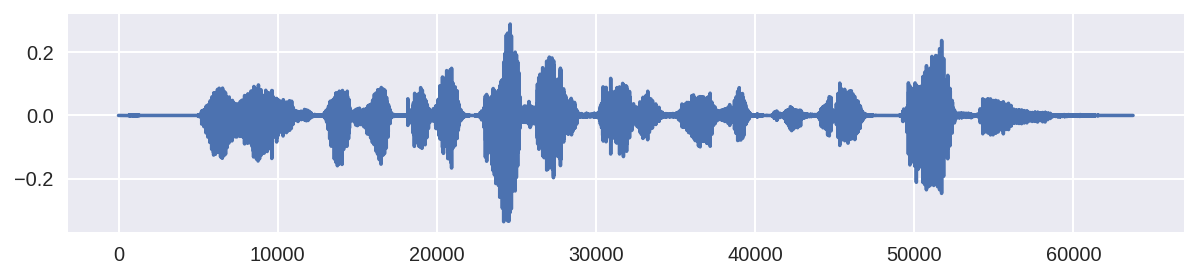

In [ ]:
plt.figure(figsize=(10, 2))
plt.plot(preemh_wave);

Обратимое преобразование. Усиливает высокие частоты, ослабляет низкие.

В вокодерах необходим для уменьшения высокочастотного шума при мю-кодировании.

In [ ]:
# STFT (можно воспользоваться librosa)
# window = 1024, hop = 256, паддинг reflect, центрировать не надо, окно Ханна

def get_stft(data, n_fft, win_length, hop, window):
  return librosa.stft(data, n_fft=n_fft, win_length=win_length, hop_length=hop, 
                      window=window, center=False, pad_mode="reflect")

stft_features = get_stft(preemh_wave, 1024, 1024, 256, "hann")

Short-time Fourier transform. Комплексные значения признаков. 

Окно анализа обычно соразмерно средней длине фонемы, шаг близким к средней длине коротких фонем (эвристические соображения от которых стоит отталкиваться).

In [ ]:
# Магнитуда (получить амплитудный спектр)

def get_magnitude(features):
  return np.abs(features)

magnitude_features = get_magnitude(stft_features)

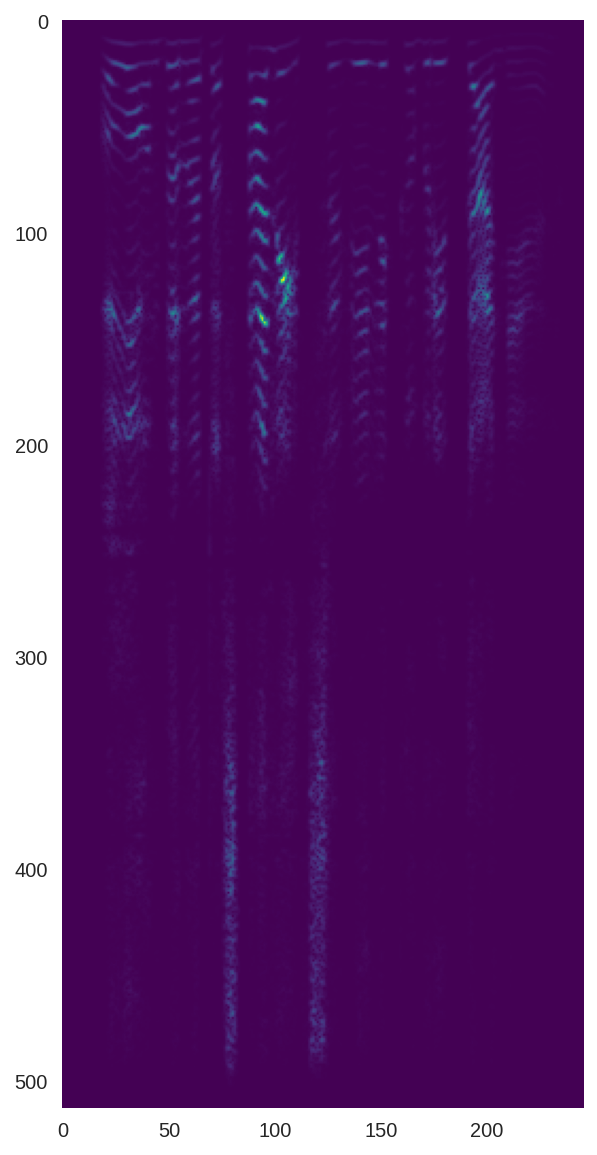

In [ ]:
plt.figure(figsize=(10, 10))
plt.imshow(magnitude_features, cmap="viridis")
plt.grid(b=None);

Теряется информация о фазе (фазовые признаки значительно менее структурированы). Признаки все еще довольно большого размера. В некоторых моделях TTS применяются и такие.

In [ ]:
# Мел-скейл. Реализуется в матричном виде как X_mel = Mel_basis * X, где Mel_basis 
# 100 бинов без ограничений частот (можно воспользоваться librosa.filters)

def get_mel_features(magnitude_features, mel_basis):
  return mel_basis @ magnitude_features

def get_mel_basis(sample_rate, size):
  return librosa.filters.mel(sr=sample_rate, n_fft=1024, n_mels=size, htk=True)

mel_basis = get_mel_basis(sr, 100)
mel_features = get_mel_features(magnitude_features, mel_basis)

In [ ]:
print(f"max {mel_features.max()} min {mel_features.min()} mean {mel_features.mean()}")

max 0.35978150367736816 min 0.0 mean 0.008176657371222973


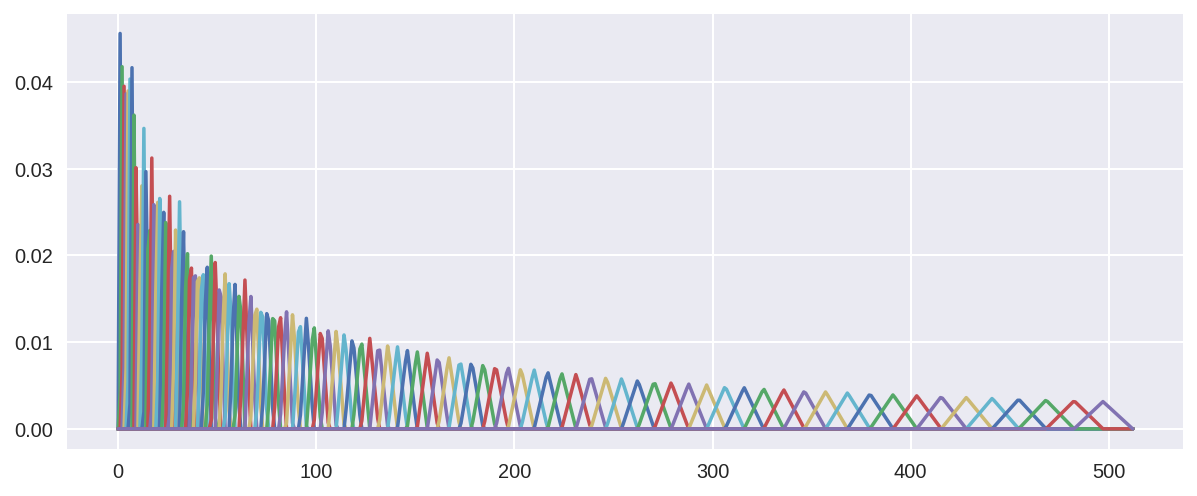

In [ ]:
plt.figure(figsize=(10, 4))
plt.plot(mel_basis.T);

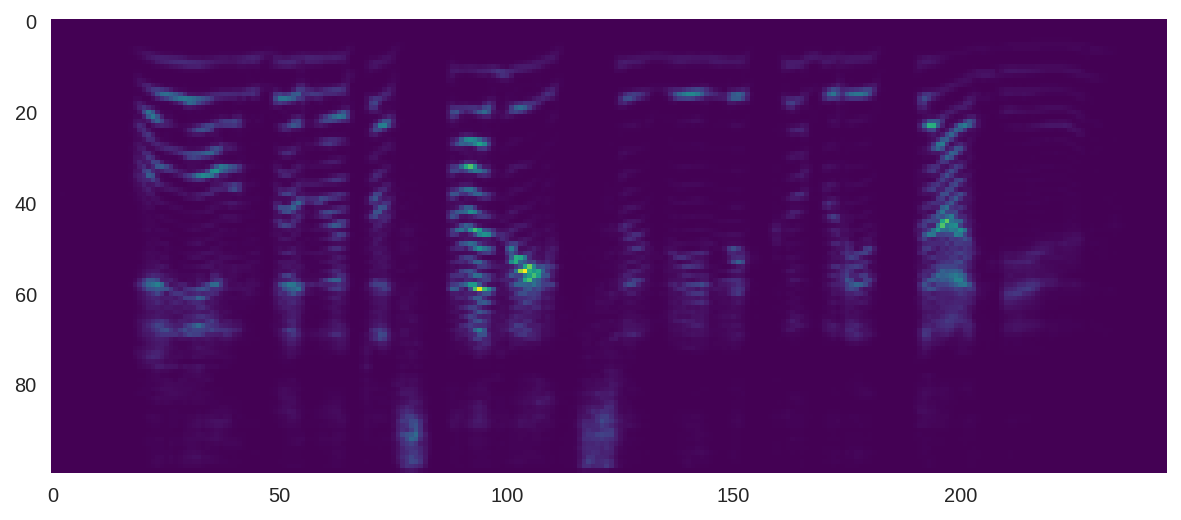

In [ ]:
plt.figure(figsize=(10, 10))
plt.imshow(mel_features, cmap="viridis")
plt.grid(b=None);

Значительно уменьшается размер признаков, при этом практически не теряется воспринимаемое акустическое качество.

In [ ]:
# Логарифмирование
# амплитуды лучше логарифмировать ln(x), 1e-5 установить минимальным значением под логарифмом (для вычислительной стабильности)
# 20log10(x) был бы перевод в децибелы, но разница в константе, поэтому можно не усложнять

def get_log_features(features):
    #return np.log(features + 1e-5)
    return np.log(np.clip(features, 1e-5, None))

log_mel_features = get_log_features(mel_features)

In [ ]:
print(f"max {log_mel_features.max()} min {log_mel_features.min()} mean {log_mel_features.mean()}")

max -1.0222584009170532 min -11.512925148010254 mean -6.940480709075928


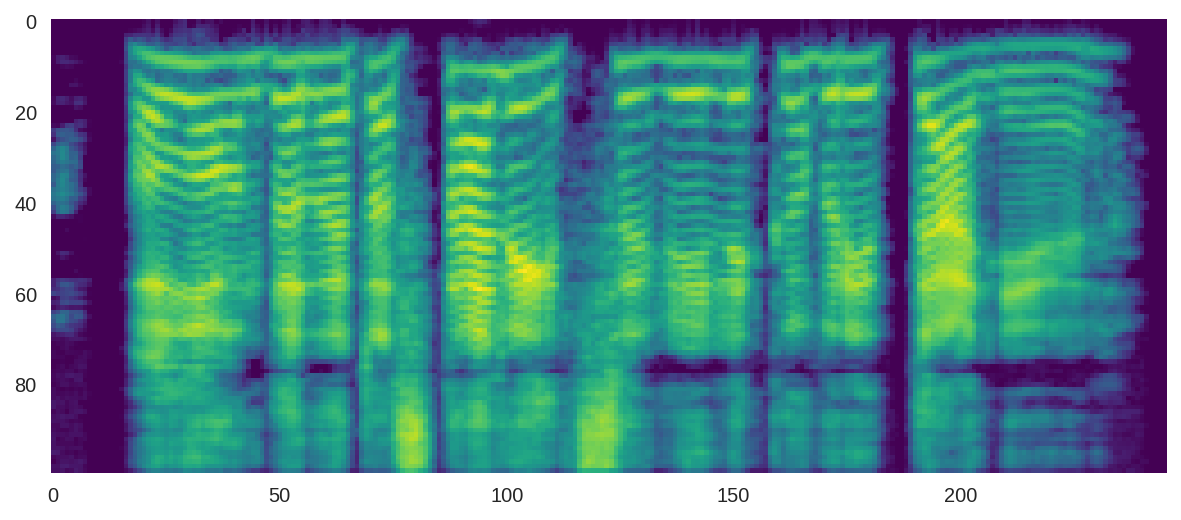

In [ ]:
plt.figure(figsize=(10, 10))
plt.imshow(log_mel_features, cmap="viridis")
plt.grid(b=None);

Такие признаки уже можно нормализовать.

Совет - посмотрите, как будут выглядеть эти же признаки без pre-emphasis.



In [ ]:
# Выгрузим результат
np.save(f"log_mel_features_{my_id}.npy", log_mel_features)
files.download(f"log_mel_features_{my_id}.npy") 

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Задание 3

Механизм внимания позволяет модели отображать последовательность фонем на спектрограмму. Базовый вариант, предложенный в модели Tacotron 1, называется content based attention.

Этот простой механизм пришел в TTS из области машинного перевода и он не учитывает многих особенностей синтеза речи. В главном это монотонный и локальный характер внимания. 

Монотонность обеспечивается тем, что порядок звуков и фонем одинаковый (если одна фонема находится в порядке после другой, то и ее признаки в спектрограмме будут находится после признаков первой, в отличие от задачи машинного перевода, где порядок слов в разных языках может отличаться). 

Локальность обеспечивается тем, что фонемы влияют на звучание только своих ближайших соседей.

Не очень подходящий механзм внимания значительно влияет на качество и естественность речи. Непрерывные длинные участки речи с ним вообще крайне затруднительно синтезировать (внимание "ломается", "рассыпается", пропадают звуки, слова, речь заедает, звучит "белиберда", ломается голос, интонации).

Разработано уже много вариантов улучшения механизма внимания. А одни из лучших способов - сразу прогнозировать длительность фонем.

Попробуем на игрушечном примере построить один из рабочих вариантов механизма внимания FORWARD ATTENTION (https://arxiv.org/pdf/1807.06736.pdf). 

In [ ]:
seq_len = 100
enc_size = 32
attn_rnn_size = 16
dec_rnn_size = 16
attn_inner_size = 32
decoder_steps = 200 # у нас нет остановки, поэтому зададим заранее количество шагов декодера

In [ ]:
# загрузим заранее сгенерированный вектор
encoder_output = torch.from_numpy(
    np.load("/content/gdrive/MyDrive/Colab Notebooks/tts_files/encoder_output.npy")
)

In [ ]:
class Attention(torch.nn.Module):
  def __init__(self, query_size, key_size, attn_inner_size):
    super(Attention, self).__init__()
    self.softmax = torch.nn.Softmax(dim=0)
    self.query = torch.nn.Linear(query_size, attn_inner_size, bias=False)
    self.key = torch.nn.Linear(key_size, attn_inner_size, bias=False)
    self.v = torch.nn.Linear(attn_inner_size, 1, bias=False)

  def forward(self, queries, keys):
    keys = self.key(keys)
    queries = self.query(queries)
    attn = self.v(torch.tanh((queries + keys)).squeeze())
    attn = self.softmax(attn)
    return attn


class SimpleAttnDecoder(torch.nn.Module):
  def __init__(self, enc_size, attn_rnn_size, dec_rnn_size, attn_inner_size):
    super(SimpleAttnDecoder, self).__init__()
    self.attn_rnn_size = attn_rnn_size
    self.dec_rnn_size = dec_rnn_size
    self.enc_size = enc_size
    self.attention = Attention(attn_rnn_size, enc_size, attn_inner_size)
    self.rnn_attn = torch.nn.RNNCell(input_size=enc_size, hidden_size=attn_rnn_size)
    self.rnn_decoder = torch.nn.RNNCell(input_size=enc_size, hidden_size=dec_rnn_size)

  def forward(self, encoder_output, output_len):
    attention_matrix = []
    outputs = []
    attention_state = torch.zeros(1, self.attn_rnn_size).float()
    decoder_state = torch.zeros(1, self.dec_rnn_size).float()
    context = torch.zeros(1, self.enc_size).float()
    forward_attention = torch.zeros(seq_len, 1).float()
    forward_attention[0, :] = 1

    for idx in range(output_len):
      attention_state = self.rnn_attn(context, attention_state)
      attention_probs = self.attention(attention_state, encoder_output)

      # forward attention - это всего-лишь модификация attention_probs 
      # допишите класс SimpleAttnDecoder, чтобы в этом месте срабатывал forward attention 
      # Algorithm 1 из предложенной статьи без transition agent
      # . . . тут вставка forward attention
      forward_attention[1:] += forward_attention[:-1].clone()
      forward_attention *= attention_probs
      forward_attention /= torch.sum(forward_attention)
      attention_probs = forward_attention.clone()

      context = torch.mm(encoder_output.squeeze().transpose(0,1), attention_probs).transpose(0,1)
      decoder_state = self.rnn_decoder(context, decoder_state)
      
      attention_matrix.append(attention_probs)
      outputs.append(decoder_state)
    
    attention_matrix = torch.stack(attention_matrix).transpose(0,1).squeeze()
    outputs = torch.stack(outputs).transpose(0,1).squeeze()
    return outputs, attention_matrix

In [ ]:
decoder = SimpleAttnDecoder(enc_size, attn_rnn_size, dec_rnn_size, attn_inner_size)
decoder.load_state_dict(torch.load("/content/gdrive/MyDrive/Colab Notebooks/tts_files/decoder_state_dict.pt"))

<All keys matched successfully>

In [ ]:
with torch.no_grad():
  outputs, attention_matrix = decoder(encoder_output, decoder_steps)

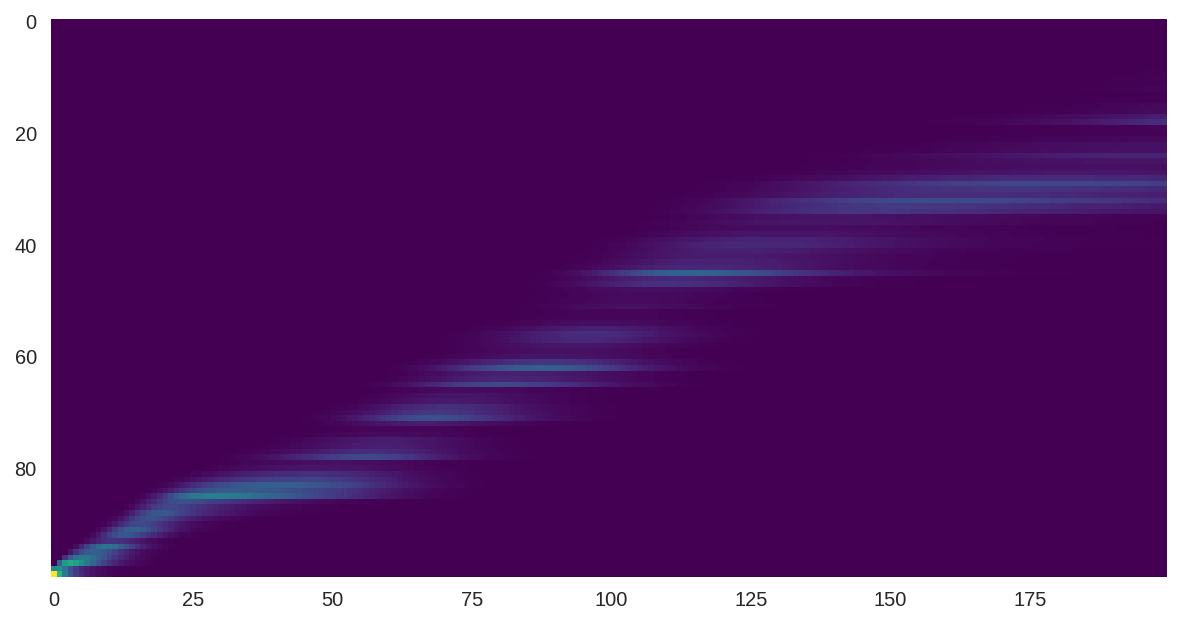

In [ ]:
plt.figure(figsize=(10, 10))
plt.imshow(attention_matrix.flip(0), cmap="viridis")
plt.grid(b=None);

In [ ]:
# Выгрузим готовый результат (матрицу внимания с реализованным forward attention)
np.save(f"attention_{my_id}.npy", attention_matrix.flip(0).numpy())
files.download(f"attention_{my_id}.npy")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Матрица внимания будет значительно диагональнее (и это модель со случайным входом и случайными весами!)